# Adaptive Gaussian Derate sampling and Julia AC-OPF verification

## 1. Imports, state/grid selection and Julia verifier

In [43]:
import csv
import hashlib
import json
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from juliacall import Main as jl

In [44]:
DATASET_NAME = "alabama"
TIME_SLICE = "16h"
DATA_DIR = Path("../power_grid/US/gridsfm_data") / TIME_SLICE
DATA_PATH = DATA_DIR / f"{DATASET_NAME}_model.json"
JULIA_SCRIPT = Path("../verifier/acopf_verifier.jl")
OUTPUT_DIR = Path("../results/gaussian_line_derate") / DATASET_NAME
SCENARIO_PATH = OUTPUT_DIR / "acopf_labeled_scenarios.npz"
DATASET_LABEL = DATASET_NAME.replace("_", " ").title()

assert DATA_PATH.is_file(), f"Grid case not found: {DATA_PATH}"
assert JULIA_SCRIPT.is_file(), f"Julia verifier not found: {JULIA_SCRIPT}"
with DATA_PATH.open("r", encoding="utf-8") as f:
    data = json.load(f)
assert isinstance(data.get("bus"), dict), "Expected case with a 'bus' dictionary"
CASE_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATASET_LABEL, "| Case:", DATA_PATH)
print("Julia verifier:", JULIA_SCRIPT)
print("Output directory:", OUTPUT_DIR)
print("Buses:", len(data["bus"]), "| baseMVA:", data.get("baseMVA"))

Dataset: Alabama | Case: ../power_grid/US/gridsfm_data/16h/alabama_model.json
Julia verifier: ../verifier/acopf_verifier.jl
Output directory: ../results/gaussian_line_derate/alabama
Buses: 494 | baseMVA: 100.0


## 2. Preserve original branch IDs and ratings

In [45]:
def is_transformer(b):
    if "transformer" in b:
        return bool(b["transformer"])
    return (abs(float(b.get("tap", 1.0)) - 1.0) > 1e-8 or
            abs(float(b.get("shift", 0.0))) > 1e-8)

branch_ids = []
for branch_id, branch in data["branch"].items():
    if int(branch.get("br_status", 1)) != 1 or is_transformer(branch):
        continue
    values = [branch.get(k, np.nan) for k in ("rate_a", "rate_b", "rate_c")]
    try:
        values = np.asarray(values, dtype=float)
    except (TypeError, ValueError):
        continue
    if values.shape == (3,) and np.isfinite(values).all() and (values > 0).all():
        branch_ids.append(str(branch_id))

branch_rates = np.asarray([[float(data["branch"][bid][k])
                            for k in ("rate_a", "rate_b", "rate_c")]
                           for bid in branch_ids], dtype=float)
n_lines = len(branch_ids)
assert n_lines >= 1, "No eligible positive-rated active non-transformer branches"
assert branch_rates.shape == (n_lines, 3)
print("Eligible non-transformer lines:", n_lines)
print("Original ratings mean [rate_a,rate_b,rate_c]:", branch_rates.mean(axis=0))

Eligible non-transformer lines: 590
Original ratings mean [rate_a,rate_b,rate_c]: [5.26623359 5.78851695 6.57786017]


## 3. Initialize the existing PowerModels AC-OPF verifier for this case

In [46]:
jl.include(str(JULIA_SCRIPT.resolve()))
summary_text = jl.ACOPFVerifier.initialize_case(str(DATA_PATH.resolve()))
print("Julia case initialized:\n", json.loads(str(summary_text)))

Julia case initialized:
 {'n_buses': 494, 'baseMVA': 100.0, 'supported_modes': ['branch', 'bus', 'gen', 'load'], 'initialized': True, 'n_loads': 494, 'n_generators': 55, 'n_branches': 864, 'per_unit': True}


## 4. Python wrapper and baseline AC-OPF check

In [47]:
def verify_scenario(patch):
    start = time.perf_counter()
    try:
        if not isinstance(patch, dict) or not patch:
            raise ValueError("patch must be a nonempty dictionary")
        raw = jl.ACOPFVerifier.verify_scenario_json(
            json.dumps(patch, allow_nan=False)
        )
        result = json.loads(str(raw))
        result["elapsed_s"] = time.perf_counter() - start
        return result
    except Exception as exc:
        return {
            "accepted": False, "status": "CALL_ERROR", "objective": None,
            "reason": str(exc)[:1000], "termination_status": "ERROR",
            "primal_status": "UNKNOWN", "elapsed_s": time.perf_counter() - start,
        }

def build_derate_patch(selected_ids, selected_ratings):
    values = np.asarray(selected_ratings, dtype=float)
    if values.shape != (len(selected_ids), 3) or not np.isfinite(values).all() or not (values > 0).all():
        raise ValueError("Expected positive finite rating triples (rate_a,rate_b,rate_c)")
    return {"branch": {
        str(bid): {"rate_a": float(vals[0]), "rate_b": float(vals[1]), "rate_c": float(vals[2])}
        for bid, vals in zip(selected_ids, values)
    }}

def verify_acopf(candidate_ratings, selected_ids):
    idx = [branch_ids.index(str(bid)) for bid in selected_ids]
    values = np.asarray(candidate_ratings, dtype=float)
    if values.shape != branch_rates.shape or not np.isfinite(values).all():
        raise ValueError(f"Expected complete candidate ratings of shape {branch_rates.shape}")
    return verify_scenario(build_derate_patch(selected_ids, values[idx]))

In [48]:
print(f"Verifying the original {DATASET_LABEL} case")
baseline_patch = build_derate_patch([branch_ids[0]], branch_rates[:1])
baseline_result = verify_scenario(baseline_patch)
print("Baseline Julia AC-OPF:", baseline_result)
if not baseline_result.get("accepted", False):
    raise RuntimeError("Original network did not pass strict AC-OPF acceptance; examine the base case/solver before sampling")

Verifying the original Alabama case
Baseline Julia AC-OPF: {'stage': 'opf', 'modes': ['branch'], 'termination_status': 'LOCALLY_SOLVED', 'objective': 198538.08988997107, 'primal_status': 'FEASIBLE_POINT', 'reason': '', 'warnings': ['Standard PowerModels AC-OPF uses rate_a for thermal constraints; rate_b/rate_c may not affect feasibility'], 'applied_components': {'branch': 1}, 'solve_time': 0.6895909309387207, 'accepted': True, 'status': 'OPF_SOLVED', 'elapsed_s': 1.1421861249837093}


## 4. Gaussian initialization

In [49]:
SEED = 42
iterations = 10
samples_per_iteration = 2
alpha = 0.30

MIN_FACTOR = 0.70
MAX_FACTOR = 0.95

fraction_rng = np.random.default_rng(SEED + 1)
FRACTION_DERATED = fraction_rng.uniform(0.1, 0.5) #Fraction of eligible lines modified per scenario

INITIAL_SCALE_MIN = 1.0
INITIAL_SCALE_MAX = 1.8

INITIAL_FACTOR_MEAN = 0.825
INITIAL_FACTOR_STD = 0.04

COV_REG = 1e-10

rng = np.random.default_rng(SEED)

scale_rng = np.random.default_rng(SEED + 2)
INITIAL_SCALE = scale_rng.uniform(
    INITIAL_SCALE_MIN,
    INITIAL_SCALE_MAX
)

factor_mu = np.array([INITIAL_FACTOR_MEAN])
factor_cov = np.array([[
    (INITIAL_SCALE * INITIAL_FACTOR_STD)**2 + COV_REG
]])
initial_factor_mu, initial_factor_cov = factor_mu.copy(), factor_cov.copy()
n_derated = min(n_lines, max(1, round(FRACTION_DERATED * n_lines)))

history, verification_log = [], []
explain_candidates, explain_labels, explain_metadata = [], [], []
selected_branch_ids_log, derate_factors_log = [], []
last_proposed, last_original, last_applied = None, None, None

print("Initial Gaussian factor mean:", factor_mu[0])
print("Initial scale:", INITIAL_SCALE, "| factor std:", np.sqrt(factor_cov[0,0]))
print("Eligible lines:", n_lines, "| derated per scenario:", n_derated)
print("Total Julia checks:", iterations*samples_per_iteration)


Initial Gaussian factor mean: 0.825
Initial scale: 1.7138140026952362 | factor std: 0.06855256083717681
Eligible lines: 590 | derated per scenario: 213
Total Julia checks: 20


## 5. Sample Derating factor and noise

In [50]:
def sample_derate(rng, original_rates, mu, cov, n_scenarios):
    n = len(original_rates)
    selected = np.stack([rng.choice(n, size=n_derated, replace=False)
                         for _ in range(n_scenarios)], axis=0)
    raw_factor = rng.multivariate_normal(mu, cov, size=(n_scenarios, n_derated),
                                         check_valid="raise")[..., 0]
    factor = np.clip(raw_factor, MIN_FACTOR, MAX_FACTOR)
    candidates = np.broadcast_to(original_rates, (n_scenarios, n, 3)).copy()
    for i in range(n_scenarios):
        candidates[i, selected[i]] = original_rates[selected[i]] * factor[i, :, None]
    assert np.isfinite(candidates).all() and (candidates > 0).all()
    assert np.all(candidates <= original_rates[None, :, :] + 1e-10)
    for i in range(n_scenarios):
        np.testing.assert_allclose(candidates[i, selected[i]] / original_rates[selected[i]],
                                   factor[i, :, None] * np.ones((1, 3)),
                                   rtol=1e-10, atol=1e-10)
    return candidates, selected, factor, raw_factor, dict(
        total_selected_lines=int(n_scenarios * n_derated),
        factor_clipped_low_count=int((raw_factor < MIN_FACTOR).sum()),
        factor_clipped_high_count=int((raw_factor > MAX_FACTOR).sum()),
        factor_clipped_fraction=float(((raw_factor < MIN_FACTOR) | (raw_factor > MAX_FACTOR)).mean()),
    )


## 6. Adaptive Gaussian loop, Julia verification and per-iteration checkpoint

In [51]:
for iteration in range(iterations):
    sampled, chosen, factors, raw_factors, diag = sample_derate(
        rng, branch_rates, factor_mu, factor_cov, samples_per_iteration)
    good_factor_list, good_rates_list = [], []
    print(f"\nIteration {iteration+1}/{iterations}: {diag['factor_clipped_fraction']:.1%} "
          f"of raw factors clipped", flush=True)

    for j in range(samples_per_iteration):
        selected_ids = [branch_ids[int(i)] for i in chosen[j]]
        verification = verify_acopf(sampled[j], selected_ids)
        row = dict(iteration=iteration+1, scenario=j+1, n_lines_derated=n_derated,
                   mean_applied_factor=float(factors[j].mean()),
                   mean_rating_reduction_pct=float(100*(1-factors[j].mean())),
                   min_applied_factor=float(factors[j].min()),
                   max_applied_factor=float(factors[j].max()),
                   **verification)
        verification_log.append(row)
        explain_candidates.append(sampled[j].astype(np.float32).copy())
        explain_labels.append(int(bool(verification.get("accepted",False))))
        explain_metadata.append((iteration+1, j+1, str(verification.get("status","UNKNOWN")),
                                 str(verification.get("termination_status","UNKNOWN"))))
        selected_branch_ids_log.append(selected_ids)
        derate_factors_log.append(factors[j].copy())
        print(f"{iteration+1}/{iterations}, scenario {j+1}/{samples_per_iteration}: "
              f"{verification.get('status')} ({verification.get('termination_status')}, "
              f"{verification.get('elapsed_s',float('nan')):.1f}s), "
              f"mean factor={factors[j].mean():.4f}", flush=True)
        if verification.get("reason"):
            print("    Reason:",str(verification["reason"])[:300],flush=True)
        if verification.get("accepted", False):
            good_factor_list.append(factors[j].copy())
            good_rates_list.append(sampled[j,chosen[j]].copy())

    accepted_count = len(good_factor_list)
    if accepted_count:
        accepted_factors = np.concatenate(good_factor_list).reshape(-1)
        new_mu = np.asarray([accepted_factors.mean()])
        new_cov = (np.asarray([[accepted_factors.var()]]) if len(accepted_factors) >= 2
                   else factor_cov.copy())
        factor_mu = (1-alpha)*factor_mu + alpha*new_mu
        factor_cov = (1-alpha)*factor_cov + alpha*new_cov
        factor_cov = 0.5*(factor_cov+factor_cov.T) + np.eye(1)*COV_REG

    history.append(dict(iteration=iteration+1, factor_mu=factor_mu.copy(),
                        factor_std=np.sqrt(np.diag(factor_cov)).copy(),
                        factor_cov=factor_cov.copy(), accepted_count=accepted_count,
                        rejected_count=samples_per_iteration-accepted_count,
                        acceptance_rate=accepted_count/samples_per_iteration,
                        updated=bool(accepted_count), **diag))
    last_proposed = raw_factors.copy()
    last_original = np.concatenate([branch_rates[chosen[j]] for j in range(samples_per_iteration)], axis=0)
    last_applied = (np.concatenate(good_rates_list, axis=0)
                    if accepted_count else np.empty((0,3)))

    np.savez_compressed(
        SCENARIO_PATH,
        candidates=np.stack(explain_candidates),
        accepted=np.asarray(explain_labels, dtype=np.int64),
        branch_ids=np.asarray(branch_ids, dtype=str),
        branch_rates=branch_rates.astype(np.float32),
        selected_branch_ids=np.asarray(selected_branch_ids_log, dtype=str),
        derate_factors=np.stack(derate_factors_log).astype(np.float32),
        iteration=np.asarray([m[0] for m in explain_metadata], dtype=np.int64),
        scenario=np.asarray([m[1] for m in explain_metadata], dtype=np.int64),
        status=np.asarray([m[2] for m in explain_metadata], dtype=str),
        termination_status=np.asarray([m[3] for m in explain_metadata], dtype=str),
        dataset_name=np.asarray(DATASET_NAME),
        source_case_sha256=np.asarray(CASE_SHA256),
        source_case_path=np.asarray(str(DATA_PATH.resolve())),
        initial_scale=np.asarray(INITIAL_SCALE),
        initial_factor_mu=initial_factor_mu.astype(float),
        initial_factor_std=np.asarray(np.sqrt(initial_factor_cov[0, 0])),
        factor_mu=factor_mu.astype(float),
        factor_std=np.asarray(np.sqrt(factor_cov[0, 0])),
        min_factor=np.asarray(MIN_FACTOR),
        max_factor=np.asarray(MAX_FACTOR),
    )
    print(f"Iteration {iteration+1}: Julia accepted {accepted_count}/{samples_per_iteration}; "
          f"factor mu={factor_mu[0]:.5f}, std={np.sqrt(factor_cov[0,0]):.5f}", flush=True)

print("Overall Julia accepted:", sum(h['accepted_count'] for h in history), "/", iterations*samples_per_iteration)
print("Saved archive:", SCENARIO_PATH)



Iteration 1/10: 7.3% of raw factors clipped
1/10, scenario 1/2: OPF_SOLVED (LOCALLY_SOLVED, 0.9s), mean factor=0.8205
1/10, scenario 2/2: OPF_SOLVED (LOCALLY_SOLVED, 0.9s), mean factor=0.8213
Iteration 1: Julia accepted 2/2; factor mu=0.82378, std=0.06768

Iteration 2/10: 7.7% of raw factors clipped
2/10, scenario 1/2: OPF_SOLVED (LOCALLY_SOLVED, 0.8s), mean factor=0.8276
2/10, scenario 2/2: NOT_VERIFIED (LOCALLY_INFEASIBLE, 4.8s), mean factor=0.8145
    Reason: AC-OPF solution not verified: termination=LOCALLY_INFEASIBLE, primal=INFEASIBLE_POINT
Iteration 2: Julia accepted 1/2; factor mu=0.82493, std=0.06721

Iteration 3/10: 8.2% of raw factors clipped
3/10, scenario 1/2: OPF_SOLVED (LOCALLY_SOLVED, 0.8s), mean factor=0.8260
3/10, scenario 2/2: OPF_SOLVED (LOCALLY_SOLVED, 0.8s), mean factor=0.8269
Iteration 3: Julia accepted 2/2; factor mu=0.82540, std=0.06635

Iteration 4/10: 5.9% of raw factors clipped
4/10, scenario 1/2: OPF_SOLVED (LOCALLY_SOLVED, 0.9s), mean factor=0.8336
4/10, 

## 7. Plots — Julia acceptance, Gaussian adaptation, and branch derating

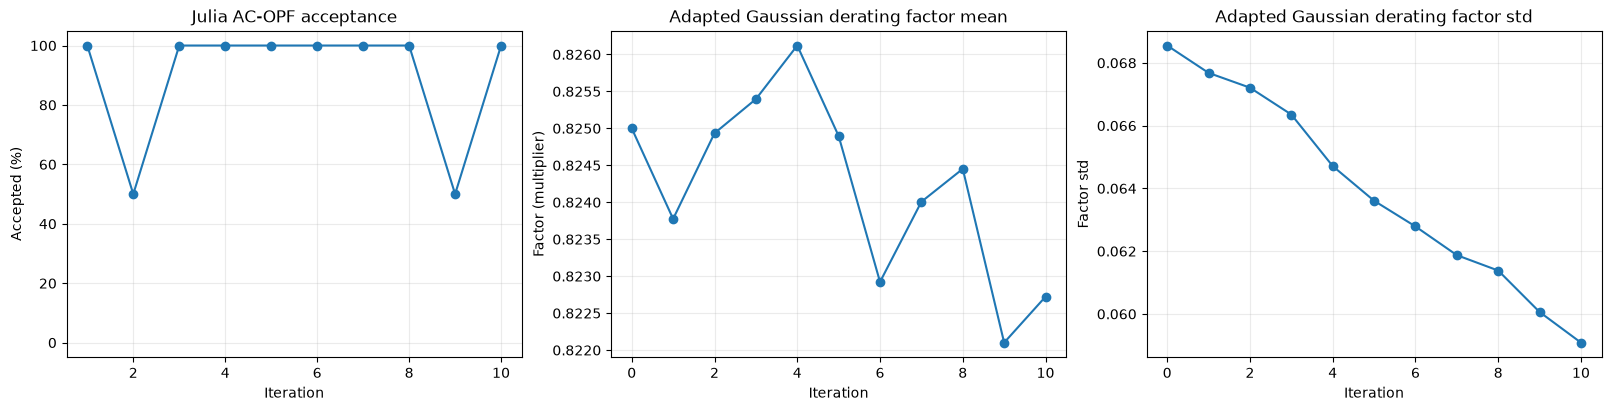

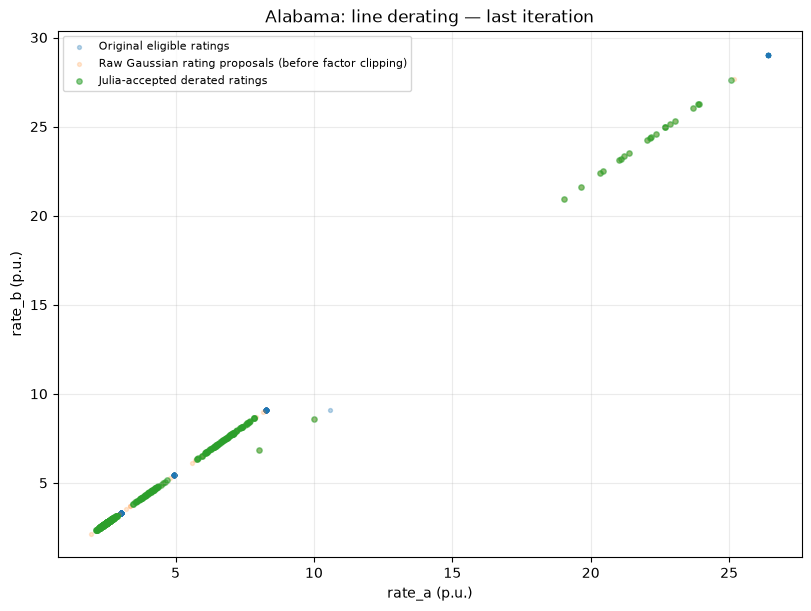

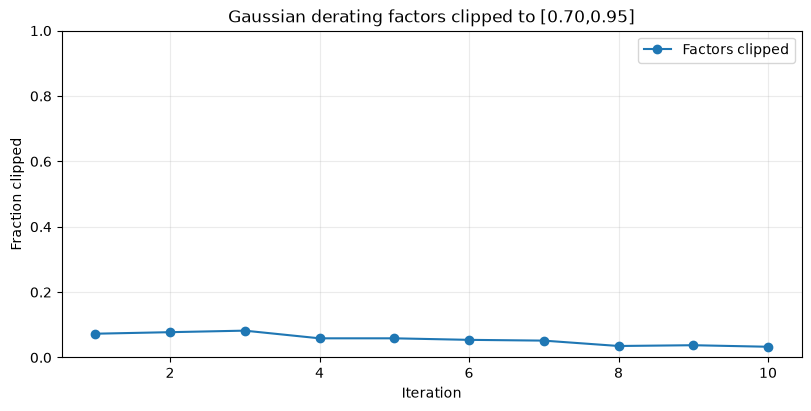

In [52]:
xs=[h["iteration"] for h in history]
fig,axes=plt.subplots(1,3,figsize=(16,4),constrained_layout=True)
axes[0].plot(xs,[100*h["acceptance_rate"] for h in history],marker="o")
axes[0].set(title="Julia AC-OPF acceptance",xlabel="Iteration",ylabel="Accepted (%)",ylim=(-5,105))
axes[1].plot([0]+xs,[initial_factor_mu[0]]+[h["factor_mu"][0] for h in history],marker="o")
axes[1].set(title="Adapted Gaussian derating factor mean",xlabel="Iteration",ylabel="Factor (multiplier)")
axes[2].plot([0]+xs,[np.sqrt(initial_factor_cov[0,0])]+[h["factor_std"][0] for h in history],marker="o")
axes[2].set(title="Adapted Gaussian derating factor std",xlabel="Iteration",ylabel="Factor std")
for ax in axes: ax.grid(alpha=.25)
fig.savefig(OUTPUT_DIR/"sampling_acceptance_and_noise.png",dpi=180,bbox_inches="tight")
plt.show()

fig,ax=plt.subplots(figsize=(8,6),constrained_layout=True)
vrng=np.random.default_rng(123)
for arr,label,size,opacity in [
    (branch_rates,"Original eligible ratings",8,.30),
    (last_original*last_proposed.reshape(-1,1),"Raw Gaussian rating proposals (before factor clipping)",8,.18),
    (last_applied,"Julia-accepted derated ratings",15,.55),
]:
    if not len(arr): continue
    points=arr[vrng.choice(len(arr),size=min(3000,len(arr)),replace=False)]
    ax.scatter(points[:,0],points[:,1],s=size,alpha=opacity,label=label,rasterized=True)
ax.set(title=f"{DATASET_LABEL}: line derating — last iteration",
       xlabel="rate_a (p.u.)",ylabel="rate_b (p.u.)")
ax.grid(alpha=.25);ax.legend(fontsize=8)
fig.savefig(OUTPUT_DIR/"branch_original_proposed_accepted.png",dpi=180,bbox_inches="tight")
plt.show()

fig,ax=plt.subplots(figsize=(8,4),constrained_layout=True)
ax.plot(xs,[h["factor_clipped_fraction"] for h in history],marker="o",label="Factors clipped")
ax.set(title="Gaussian derating factors clipped to [0.70,0.95]",xlabel="Iteration",
       ylabel="Fraction clipped",ylim=(0,1))
ax.grid(alpha=.25);ax.legend()
fig.savefig(OUTPUT_DIR/"derate_clipping_fractions.png",dpi=180,bbox_inches="tight")
plt.show()

## 8. Export verification and Gaussian history CSVs

In [53]:
def write_csv(path, rows, fields):
    with path.open("w",newline="",encoding="utf-8") as f:
        writer=csv.DictWriter(f,fieldnames=fields,extrasaction="ignore")
        writer.writeheader(); writer.writerows(rows)

log_fields=["iteration","scenario","accepted","status","termination_status",
            "primal_status","objective","solve_time","elapsed_s","reason",
            "n_lines_derated","mean_applied_factor","mean_rating_reduction_pct",
            "min_applied_factor","max_applied_factor"]
write_csv(OUTPUT_DIR/"verification_log.csv",verification_log,log_fields)
history_rows=[dict(iteration=h["iteration"],accepted_count=h["accepted_count"],
                   rejected_count=h["rejected_count"],acceptance_rate=h["acceptance_rate"],
                   updated=h["updated"],factor_mu=float(h["factor_mu"][0]),
                   factor_std=float(h["factor_std"][0]),
                   factor_clipped_fraction=h["factor_clipped_fraction"],
                   factor_clipped_low_count=h["factor_clipped_low_count"],
                   factor_clipped_high_count=h["factor_clipped_high_count"],
                   total_selected_lines=h["total_selected_lines"]) for h in history]
write_csv(OUTPUT_DIR/"sampling_history.csv",history_rows,list(history_rows[0]))
print("Saved:",OUTPUT_DIR)

Saved: ../results/gaussian_line_derate/alabama
